In [ ]:
##Sales Data Analysis Portfolio Project
##Objective: To analyse retail sales data using Python, identify sales trends and product performance, and communicate insights through visualisations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Sample sales dataset
data = {
    "Product": ["Laptop", "Mouse", "Keyboard", "Monitor", "Headphones",
                "Mouse", "Laptop", "Keyboard", "Monitor", "Headphones"],
    "Category": ["Electronics", "Accessories", "Accessories",
                 "Electronics", "Accessories", "Accessories",
                 "Electronics", "Accessories", "Electronics", "Accessories"],
    "Units_Sold": [2, 15, 8, 3, 10, 12, 1, 6, 2, 7],
    "Unit_Price": [45000, 500, 1200, 12000, 1800,
                   500, 45000, 1200, 12000, 1800]
}

df = pd.DataFrame(data)

# Calculate revenue for each row
df["Revenue"] = df["Units_Sold"] * df["Unit_Price"]

# Display the first five rows
df.head()

,Product,Category,Units_Sold,Unit_Price,Revenue
0,Laptop,Electronics,2,45000,90000
1,Mouse,Accessories,15,500,7500
2,Keyboard,Accessories,8,1200,9600
3,Monitor,Electronics,3,12000,36000
4,Headphones,Accessories,10,1800,18000


In [2]:
# Basic information about the dataset
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
print(df.describe())

Dataset shape: (10, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Product     10 non-null     object
 1   Category    10 non-null     object
 2   Units_Sold  10 non-null     int64 
 3   Unit_Price  10 non-null     int64 
 4   Revenue     10 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 532.0+ bytes

Missing values:
Product       0
Category      0
Units_Sold    0
Unit_Price    0
Revenue       0
dtype: int64

Duplicate rows: 0

Summary statistics:
       Units_Sold    Unit_Price       Revenue
count   10.000000     10.000000     10.000000
mean     6.600000  12100.000000  25590.000000
std      4.718757  17900.217255  26177.872335
min      1.000000    500.000000   6000.000000
25%      2.250000   1200.000000   8025.000000
50%      6.500000   1800.000000  15300.000000
75%      9.500000  12000.000000  33000.000000
ma

In [3]:
# 1. Total revenue
total_revenue = df["Revenue"].sum()
print(f"Total revenue: Rs. {total_revenue:,.2f}")

# 2. Total units sold
total_units = df["Units_Sold"].sum()
print(f"Total units sold: {total_units}")

# 3. Revenue by product
product_revenue = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by product:")
print(product_revenue)

# 4. Units sold by product
product_units = (
    df.groupby("Product")["Units_Sold"]
    .sum()
    .sort_values(ascending=False)
)

print("\nUnits sold by product:")
print(product_units)

# 5. Revenue by category
category_revenue = (
    df.groupby("Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by category:")
print(category_revenue)

Total revenue: Rs. 255,900.00
Total units sold: 66

Revenue by product:
Product
Laptop        135000
Monitor        60000
Headphones     30600
Keyboard       16800
Mouse          13500
Name: Revenue, dtype: int64

Units sold by product:
Product
Mouse         27
Headphones    17
Keyboard      14
Monitor        5
Laptop         3
Name: Units_Sold, dtype: int64

Revenue by category:
Category
Electronics    195000
Accessories     60900
Name: Revenue, dtype: int64


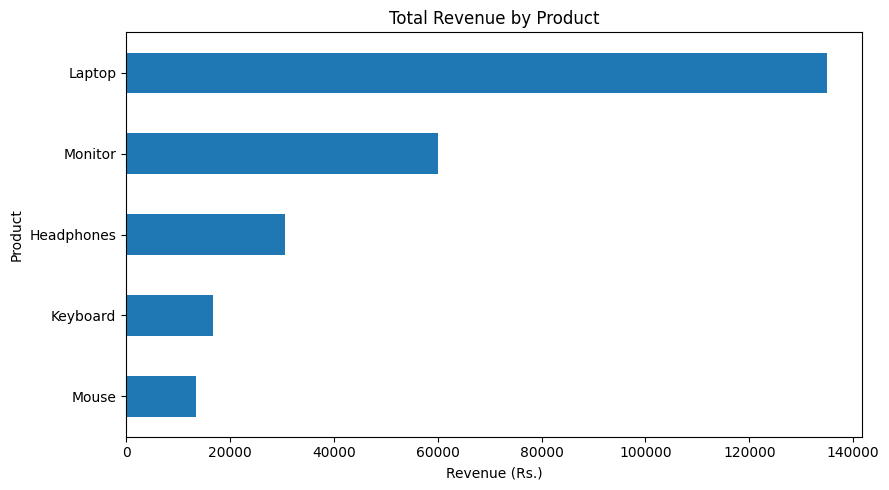

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

product_revenue.sort_values().plot(
    kind="barh",
    title="Total Revenue by Product"
)

plt.xlabel("Revenue (Rs.)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

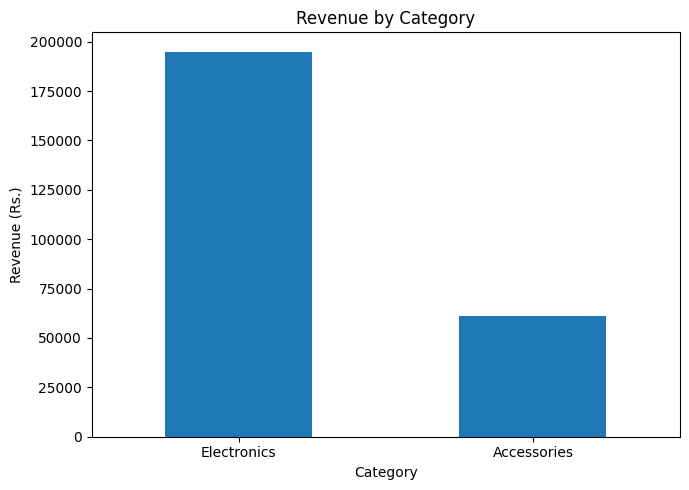

In [5]:
plt.figure(figsize=(7, 5))

category_revenue.plot(
    kind="bar",
    title="Revenue by Category"
)

plt.xlabel("Category")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Business summary

total_revenue = df["Revenue"].sum()
total_units = df["Units_Sold"].sum()

product_revenue = df.groupby("Product")["Revenue"].sum()
product_units = df.groupby("Product")["Units_Sold"].sum()

top_revenue_product = product_revenue.idxmax()
top_units_product = product_units.idxmax()

print("=" * 45)
print("         SALES ANALYSIS REPORT")
print("=" * 45)

print(f"Total Revenue: Rs. {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units}")
print(f"Top Revenue Product: {top_revenue_product}")
print(f"Top Units Sold Product: {top_units_product}")

print("\nBUSINESS OBSERVATIONS")
print("-" * 45)
print(f"1. {top_revenue_product} generated the highest revenue.")
print(f"2. {top_units_product} had the highest unit sales.")
print("3. Revenue and unit sales measure different aspects")
print("   of product performance.")

         SALES ANALYSIS REPORT
Total Revenue: Rs. 255,900.00
Total Units Sold: 66
Top Revenue Product: Laptop
Top Units Sold Product: Mouse

BUSINESS OBSERVATIONS
---------------------------------------------
1. Laptop generated the highest revenue.
2. Mouse had the highest unit sales.
3. Revenue and unit sales measure different aspects
   of product performance.


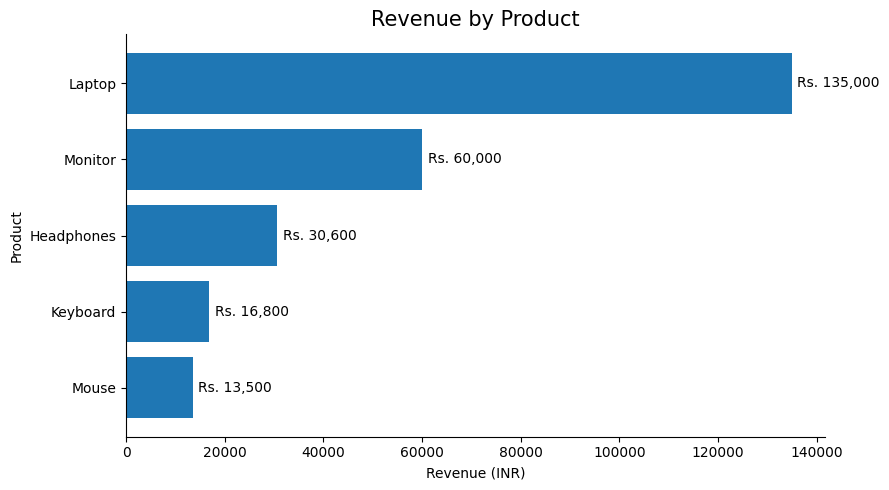

In [7]:
import matplotlib.pyplot as plt

revenue_by_product = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    revenue_by_product.index,
    revenue_by_product.values
)

ax.set_title("Revenue by Product", fontsize=15)
ax.set_xlabel("Revenue (INR)")
ax.set_ylabel("Product")

ax.bar_label(
    bars,
    labels=[f"Rs. {v:,.0f}" for v in revenue_by_product.values],
    padding=4
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("revenue_by_product.png", dpi=200, bbox_inches="tight")
plt.show()

## Sales Data Analysis — Key Findings

**Objective:** Analyse a sample retail dataset to understand product sales and revenue performance.

**Findings**
1. The laptop category of products generated the highest revenue among the individual products.
2. The mouse had the highest number of units sold.
3. Unit sales and revenue provide different perspectives on product performance.
4. Product-level revenue comparisons can help businesses investigate which items contribute most to sales.

**Recommendations**
- Monitor revenue and unit sales separately.
- Review demand and stock availability for high-volume products.
- Investigate the profitability of high-revenue products using cost data.
- Analyse sales over time before making decisions about seasonal demand.

**Limitations:** This project uses a small illustrative dataset, not actual business records. It does not include dates, costs, profit margins, or customer information. Therefore, the findings cannot establish trends, profitability, or future demand.